In [15]:

import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")


Libraries imported successfully!


In [18]:

print("Hello! My Data Analytics Internship has started.")
print("I am learning Python from zero.")
print("Today is my first day!")


Hello! My Data Analytics Internship has started.
I am learning Python from zero.
Today is my first day!


In [21]:

name = "Student"
age = 19
course = "Data Analytics"

print(name)
print(age)
print(course)


Student
19
Data Analytics


In [22]:

x = 50
y = 20

print(x + y)
print(x - y)


70
30


In [23]:

import pandas as pd

print("Pandas is ready!")


Pandas is ready!


In [25]:
import pandas as pd

url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv"

df = pd.read_csv(url)

print("Dataset successfully loaded!")

print(df.head())

Dataset successfully loaded!
   survived  pclass     sex   age  sibsp  parch     fare embarked  class  \
0         0       3    male  22.0      1      0   7.2500        S  Third   
1         1       1  female  38.0      1      0  71.2833        C  First   
2         1       3  female  26.0      0      0   7.9250        S  Third   
3         1       1  female  35.0      1      0  53.1000        S  First   
4         0       3    male  35.0      0      0   8.0500        S  Third   

     who  adult_male deck  embark_town alive  alone  
0    man        True  NaN  Southampton    no  False  
1  woman       False    C    Cherbourg   yes  False  
2  woman       False  NaN  Southampton   yes   True  
3  woman       False    C  Southampton   yes  False  
4    man        True  NaN  Southampton    no   True  


In [26]:

# Check dataset shape
print("Dataset Shape:", df.shape)

# Check column names
print("\nColumn Names:")
print(df.columns)

# Check data information
print("\nDataset Information:")
df.info()


Dataset Shape: (891, 15)

Column Names:
Index(['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare',
       'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town',
       'alive', 'alone'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    object 
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    object 
 8   class        891 non-null    object 
 9   who          891 non-null    object 
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    object 
 12  embark_town  889 non-null    object 
 13  alive    

In [27]:

print("Missing Values in Each Column:")
print(df.isnull().sum())


Missing Values in Each Column:
survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64


In [28]:

# Check duplicate records

duplicates = df.duplicated().sum()

print("Total Duplicate Records:", duplicates)

# Check data types
print("\nData Types:")
print(df.dtypes)


Total Duplicate Records: 107

Data Types:
survived         int64
pclass           int64
sex             object
age            float64
sibsp            int64
parch            int64
fare           float64
embarked        object
class           object
who             object
adult_male        bool
deck            object
embark_town     object
alive           object
alone             bool
dtype: object


In [29]:

# Create a copy of original dataset
clean_df = df.copy()

# Remove exact duplicate records
clean_df = clean_df.drop_duplicates()

# Fill missing age with median
clean_df['age'] = clean_df['age'].fillna(
    clean_df['age'].median()
)

# Fill missing embarked with mode
clean_df['embarked'] = clean_df['embarked'].fillna(
    clean_df['embarked'].mode()[0]
)

# Fill missing embark_town with mode
clean_df['embark_town'] = clean_df['embark_town'].fillna(
    clean_df['embark_town'].mode()[0]
)

# Remove deck column because it has many missing values
clean_df = clean_df.drop(columns=['deck'])

print("Data cleaning completed!")
print("Remaining missing values:")
print(clean_df.isnull().sum())


Data cleaning completed!
Remaining missing values:
survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    0
alive          0
alone          0
dtype: int64


In [30]:

# Check cleaned dataset
print("Original Dataset:", df.shape)
print("Cleaned Dataset:", clean_df.shape)

# Check duplicates again
print("Remaining Duplicates:", clean_df.duplicated().sum())

# Save as CSV file
clean_df.to_csv("titanic_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")


Original Dataset: (891, 15)
Cleaned Dataset: (784, 14)
Remaining Duplicates: 4
Cleaned dataset saved successfully!


In [31]:

from google.colab import files
files.download("titanic_cleaned.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


TASK 2 – EXPLORATORY DATA ANALYSIS (EDA)


In [32]:

# TASK 2: Dataset Overview

print("Dataset Overview")

# Total rows and columns
print("\nDataset Shape:")
print(clean_df.shape)

# First five records
print("\nFirst Five Records:")
display(clean_df.head())

# Statistical summary
print("\nStatistical Summary:")
display(clean_df.describe())

# Information about dataset
print("\nDataset Information:")
clean_df.info()


Dataset Overview

Dataset Shape:
(784, 14)

First Five Records:


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,Southampton,no,True



Statistical Summary:


,survived,pclass,age,sibsp,parch,fare
count,784.000000,784.000000,784.000000,784.000000,784.000000,784.000000
mean,0.411990,2.243622,29.650408,0.522959,0.415816,34.711740
std,0.492507,0.855056,13.734925,0.986231,0.836922,52.160151
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,1.000000,22.000000,0.000000,0.000000,8.050000
50%,0.000000,3.000000,28.250000,0.000000,0.000000,15.900000
75%,1.000000,3.000000,36.000000,1.000000,1.000000,34.109350
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
Index: 784 entries, 0 to 890
Data columns (total 14 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     784 non-null    int64  
 1   pclass       784 non-null    int64  
 2   sex          784 non-null    object 
 3   age          784 non-null    float64
 4   sibsp        784 non-null    int64  
 5   parch        784 non-null    int64  
 6   fare         784 non-null    float64
 7   embarked     784 non-null    object 
 8   class        784 non-null    object 
 9   who          784 non-null    object 
 10  adult_male   784 non-null    bool   
 11  embark_town  784 non-null    object 
 12  alive        784 non-null    object 
 13  alone        784 non-null    bool   
dtypes: bool(2), float64(2), int64(4), object(6)
memory usage: 81.2+ KB


In [33]:

print("Duplicate records:")
print(clean_df.duplicated().sum())

print("\nDuplicate rows:")
display(clean_df[clean_df.duplicated(keep=False)])


Duplicate records:
4

Duplicate rows:


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,embark_town,alive,alone
126,0,3,male,28.25,0,0,7.75,Q,Third,man,True,Queenstown,no,True
252,0,1,male,62.00,0,0,26.55,S,First,man,True,Southampton,no,True
327,1,2,female,36.00,0,0,13.00,S,Second,woman,False,Southampton,yes,True
387,1,2,female,36.00,0,0,13.00,S,Second,woman,False,Southampton,yes,True
555,0,1,male,62.00,0,0,26.55,S,First,man,True,Southampton,no,True
633,0,1,male,28.25,0,0,0.00,S,First,man,True,Southampton,no,True
776,0,3,male,28.25,0,0,7.75,Q,Third,man,True,Queenstown,no,True
815,0,1,male,28.25,0,0,0.00,S,First,man,True,Southampton,no,True


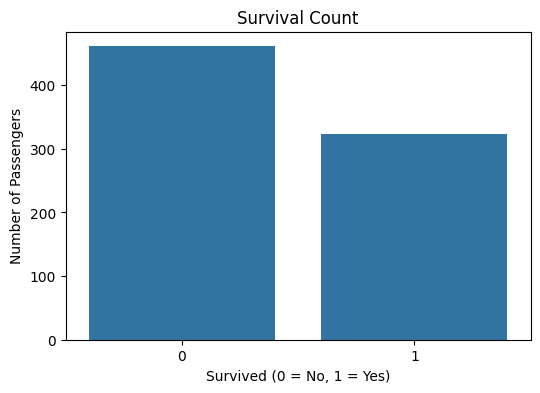

In [34]:
# Survival Count Graph

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 4))

sns.countplot(data=clean_df, x='survived')

plt.title("Survival Count")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")

plt.show()

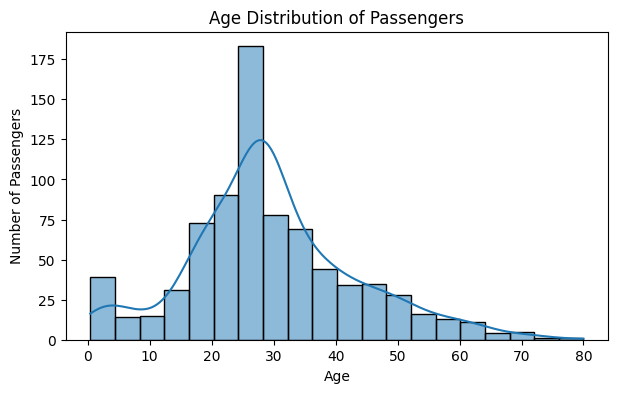

In [35]:
plt.figure(figsize=(7,4))

sns.histplot(data=clean_df, x='age', bins=20, kde=True)

plt.title("Age Distribution of Passengers")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")

plt.show()

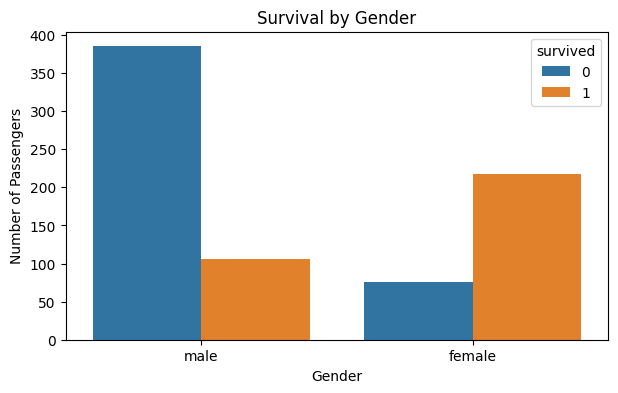

In [36]:
plt.figure(figsize=(7,4))

sns.countplot(data=clean_df, x='sex', hue='survived')

plt.title("Survival by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Passengers")

plt.show()

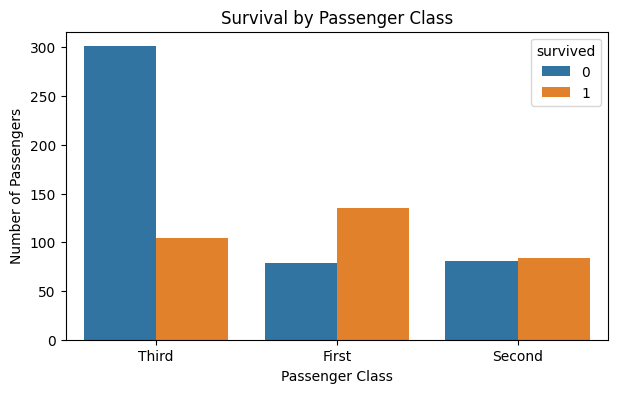

In [37]:

plt.figure(figsize=(7,4))

sns.countplot(data=clean_df, x='class', hue='survived')

plt.title("Survival by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Number of Passengers")

plt.show()


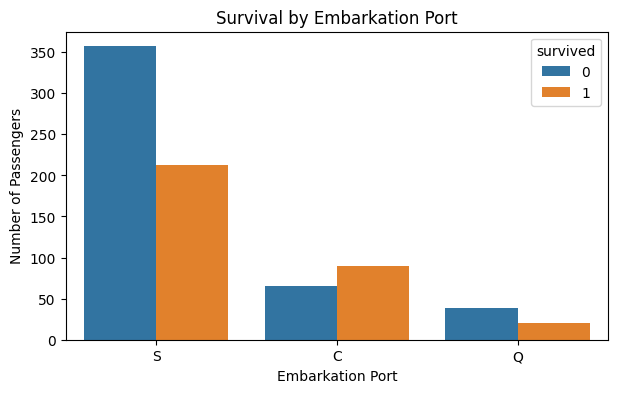

In [38]:

plt.figure(figsize=(7,4))

sns.countplot(data=clean_df, x='embarked', hue='survived')

plt.title("Survival by Embarkation Port")
plt.xlabel("Embarkation Port")
plt.ylabel("Number of Passengers")

plt.show()


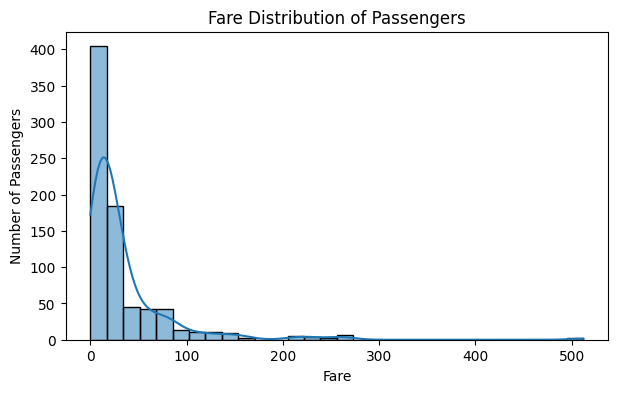

In [39]:

plt.figure(figsize=(7,4))

sns.histplot(data=clean_df, x='fare', bins=30, kde=True)

plt.title("Fare Distribution of Passengers")
plt.xlabel("Fare")
plt.ylabel("Number of Passengers")

plt.show()


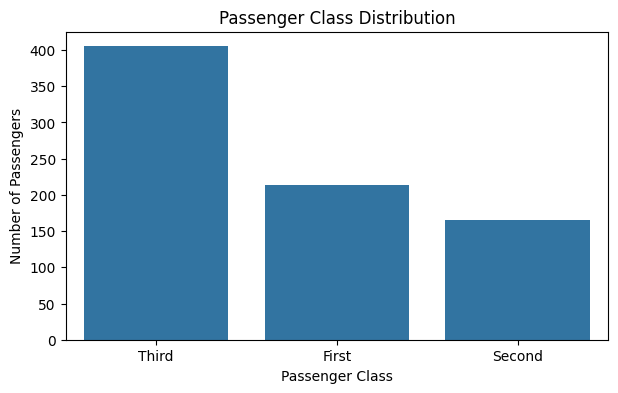

In [40]:

plt.figure(figsize=(7,4))

sns.countplot(data=clean_df, x='class')

plt.title("Passenger Class Distribution")
plt.xlabel("Passenger Class")
plt.ylabel("Number of Passengers")

plt.show()


In [41]:

print("EDA Analysis Completed Successfully!")
print("Total Graphs Created: 7")
print("Dataset Shape:", clean_df.shape)
print("EDA Task 2 Completed!")


EDA Analysis Completed Successfully!
Total Graphs Created: 7
Dataset Shape: (784, 14)
EDA Task 2 Completed!


TASK3 - DATA VISUALIZATION

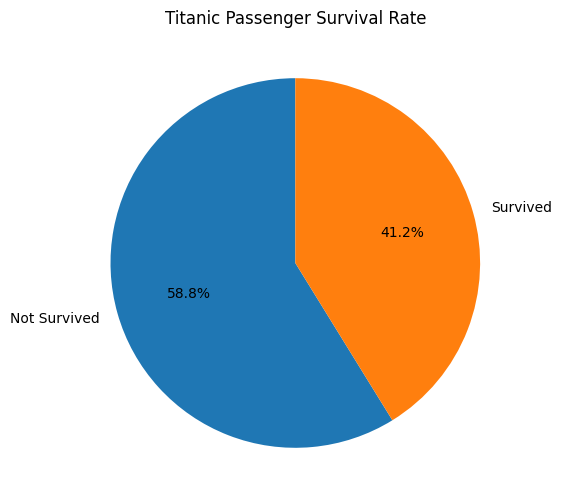

In [42]:

survival_counts = clean_df['survived'].value_counts()

plt.figure(figsize=(6,6))

plt.pie(
    survival_counts,
    labels=['Not Survived', 'Survived'],
    autopct='%1.1f%%',
    startangle=90
)

plt.title("Titanic Passenger Survival Rate")
plt.show()


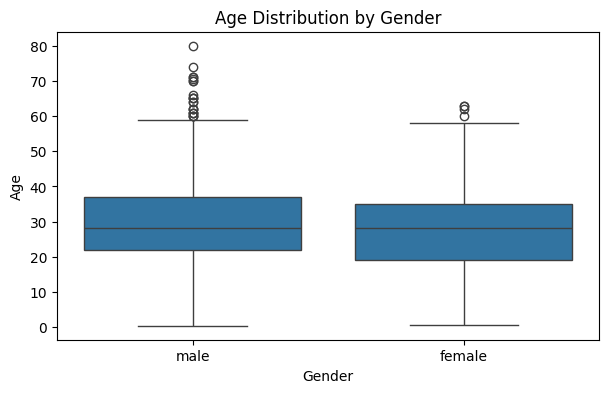

In [43]:

plt.figure(figsize=(7,4))

sns.boxplot(data=clean_df, x='sex', y='age')

plt.title("Age Distribution by Gender")
plt.xlabel("Gender")
plt.ylabel("Age")

plt.show()


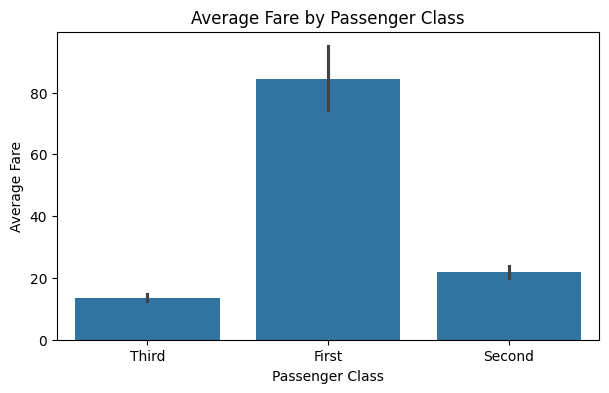

In [44]:
plt.figure(figsize=(7,4))

sns.barplot(data=clean_df, x='class', y='fare')

plt.title("Average Fare by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Average Fare")

plt.show()

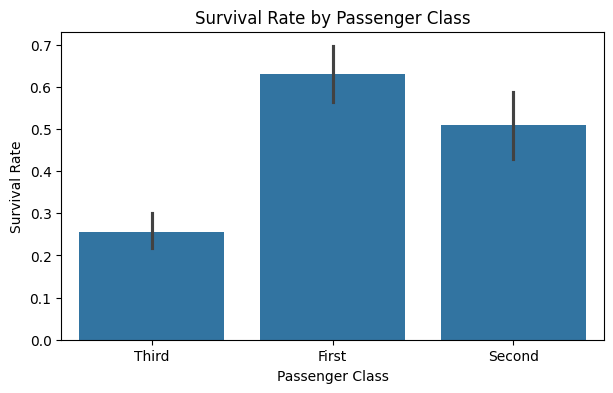

In [45]:
plt.figure(figsize=(7,4))

sns.barplot(data=clean_df, x='class', y='survived')

plt.title("Survival Rate by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate")

plt.show()

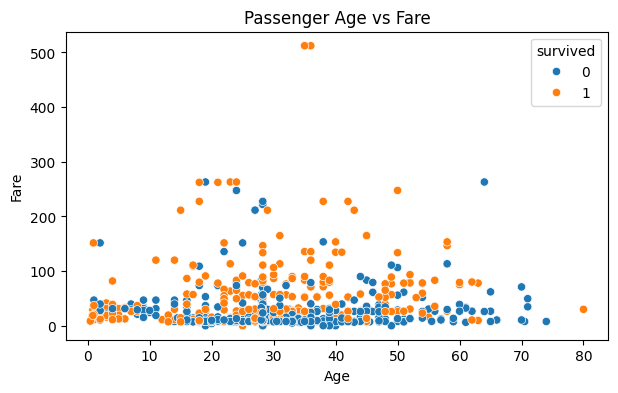

In [46]:
plt.figure(figsize=(7,4))

sns.scatterplot(data=clean_df, x='age', y='fare', hue='survived')

plt.title("Passenger Age vs Fare")
plt.xlabel("Age")
plt.ylabel("Fare")

plt.show()

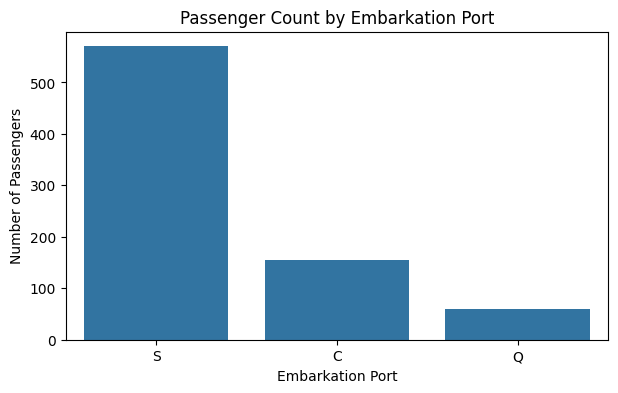

In [47]:
plt.figure(figsize=(7,4))

sns.countplot(data=clean_df, x='embarked')

plt.title("Passenger Count by Embarkation Port")
plt.xlabel("Embarkation Port")
plt.ylabel("Number of Passengers")

plt.show()

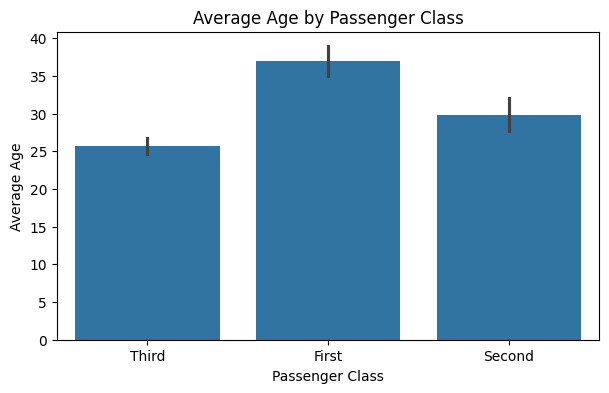

In [48]:
plt.figure(figsize=(7,4))

sns.barplot(data=clean_df, x='class', y='age')

plt.title("Average Age by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Average Age")

plt.show()

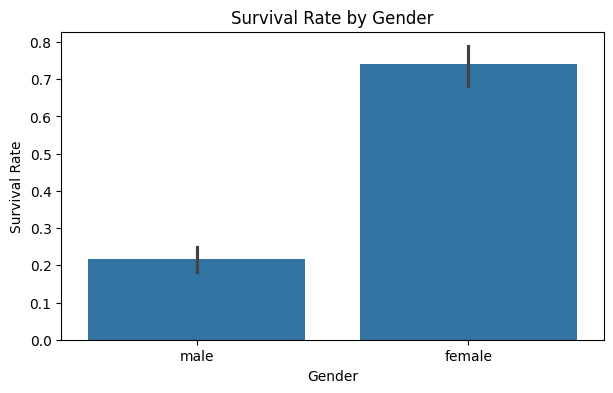

In [49]:
plt.figure(figsize=(7,4))

sns.barplot(data=clean_df, x='sex', y='survived')

plt.title("Survival Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Survival Rate")

plt.show()


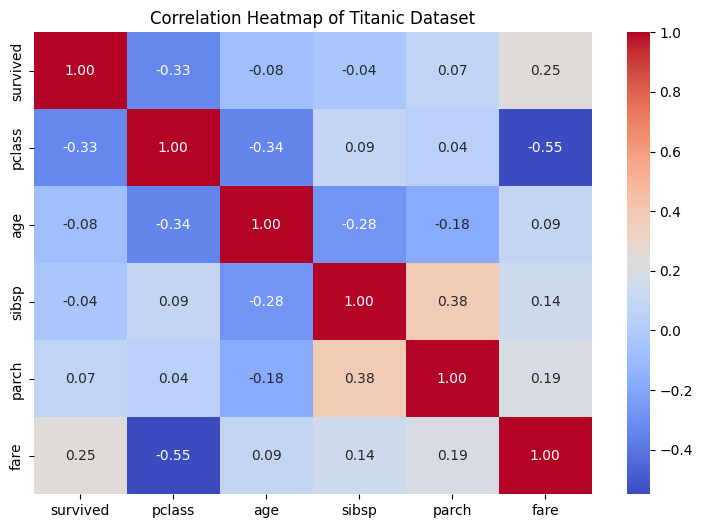

In [50]:
plt.figure(figsize=(9,6))

numeric_df = clean_df.select_dtypes(include='number')

sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt='.2f')

plt.title("Correlation Heatmap of Titanic Dataset")

plt.show()